# Proyek Analisis Data: Beijing Multi-Site Air Quality
- **Nama:** Galih Rasyid Maulana
- **Email:** rasyidmaulreal@gmail.com
- **ID Dicoding:** [Isi username akun Dicoding, bukan ID program]

Analisis deskriptif PM2.5 pada 12 stasiun Beijing, 1 Maret 2013–28 Februari 2017.
Struktur mengikuti templat notebook yang disediakan: pertanyaan bisnis, wrangling,
EDA, visualisasi, analisis lanjutan, serta kesimpulan dan rekomendasi.

Sumber: Chen, S. (2017), [Beijing Multi-Site Air Quality, UCI](https://doi.org/10.24432/C5RK5G),
lisensi CC BY 4.0. CSV asli disertakan tanpa perubahan dalam `data/`.
Satuan PM2.5 adalah µg/m³. Data historis ini tidak menggambarkan kondisi udara saat ini.

## Menentukan Pertanyaan Bisnis

**Pertanyaan 1 — prioritas lokasi**
> Selama 1 Maret 2013–28 Februari 2017, tiga stasiun mana yang memiliki rata-rata PM2.5 harian tertinggi, berapa nilai rata-rata dan persentase hari validnya, sebagai dasar penentuan prioritas audit pemantauan kualitas udara?

**Pertanyaan 2 — prioritas waktu**
> Selama 1 Maret 2013–28 Februari 2017, bulan kalender apa yang memiliki rata-rata PM2.5 tertinggi dan terendah, serta berapa selisihnya, sebagai dasar penjadwalan peningkatan pemantauan kualitas udara?

| Unsur SMART | Pertanyaan 1 | Pertanyaan 2 |
| --- | --- | --- |
| Specific | Membandingkan rata-rata PM2.5 harian antarstasiun dan memilih tiga tertinggi. | Membandingkan rata-rata PM2.5 menurut bulan kalender. |
| Measurable | Rata-rata dalam µg/m³ dan persentase hari valid per stasiun. | Rata-rata tertinggi, terendah, dan selisih dalam µg/m³. |
| Action-oriented | Menentukan prioritas audit pemantauan. | Menentukan jadwal peningkatan pemantauan. |
| Relevant | Mendukung pengelola pemantauan dalam menentukan prioritas lokasi. | Mendukung pengelola pemantauan dalam menentukan prioritas waktu. |
| Time-bound | 1 Maret 2013–28 Februari 2017. | 1 Maret 2013–28 Februari 2017. |

Unit analisis adalah **stasiun-hari**. Hari valid memiliki ≥18 pengamatan PM2.5
per jam (75% kelengkapan), aturan analitis proyek. Persentase hari valid adalah
jumlah hari valid dibagi seluruh 1.461 hari pada periode penelitian ×100%.
Rata-rata per stasiun dihitung dari hari valid, bukan total konsentrasi yang akan
terpengaruh perbedaan jumlah hari teramati.

Untuk pertanyaan 2, hitung rata-rata tiap stasiun-bulan-tahun, kemudian rata-rata
antarstasiun dengan bobot setara, lalu rata-rata antar-tahun untuk bulan kalender
yang sama. Januari–Februari menggunakan 2014–2017, sedangkan Maret–Desember
menggunakan 2013–2016. Hasil merupakan pola bulan kalender dalam periode tersebut.
Analisis lanjutan mengenai proporsi kelompok konsentrasi melengkapi kedua jawaban.

## Import Semua Packages/Library yang Digunakan

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

BASE = Path.cwd()
if not (BASE / 'data').exists():
    BASE = BASE / 'submission'
(BASE / 'figures').mkdir(parents=True, exist_ok=True)
START_DATE = pd.Timestamp('2013-03-01')
END_DATE = pd.Timestamp('2017-02-28')
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.titleweight': 'bold'})
pd.set_option('display.max_columns', 20)
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'Mei', 'Jun', 'Jul', 'Agu', 'Sep', 'Okt', 'Nov', 'Des']
LABELS = ['0–25', '>25–50', '>50–100', '>100–150', '>150']
COLORS = ['#d9e8f5', '#9ac3df', '#5097c2', '#25618f', '#123b5d']

## Data Wrangling

### Gathering Data
Muat seluruh CSV sebagai DataFrame dan gabungkan vertikal. Masing-masing baris mewakili
satu jam di satu stasiun. Kolom `No` hanyalah nomor urut dalam berkas, bukan ID global.
Variabel meteorologi dan polutan lain dipertahankan dalam data mentah, tetapi fokus analisis adalah PM2.5.

In [2]:
files = sorted((BASE / 'data').glob('PRSA_Data_*.csv'))
assert len(files) == 12, 'Diperlukan 12 CSV stasiun.'
raw = pd.concat([pd.read_csv(path) for path in files], ignore_index=True)
display(raw.head())
display(raw.groupby('station').size().rename('jumlah_baris').to_frame())
print(f'{len(raw):,} baris, {raw.shape[1]} kolom; {raw.station.nunique()} stasiun')
source_dates = pd.to_datetime(raw[['year', 'month', 'day']])
assert source_dates.between(START_DATE, END_DATE).all()
print(f'Periode sumber: {source_dates.min():%d-%m-%Y} sampai {source_dates.max():%d-%m-%Y}')

,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station
0,1,2013,3,1,0,4.0,4.0,4.0,7.0,300.0,77.0,-0.7,1023.0,-18.8,0.0,NNW,4.4,Aotizhongxin
1,2,2013,3,1,1,8.0,8.0,4.0,7.0,300.0,77.0,-1.1,1023.2,-18.2,0.0,N,4.7,Aotizhongxin
2,3,2013,3,1,2,7.0,7.0,5.0,10.0,300.0,73.0,-1.1,1023.5,-18.2,0.0,NNW,5.6,Aotizhongxin
3,4,2013,3,1,3,6.0,6.0,11.0,11.0,300.0,72.0,-1.4,1024.5,-19.4,0.0,NW,3.1,Aotizhongxin
4,5,2013,3,1,4,3.0,3.0,12.0,12.0,300.0,72.0,-2.0,1025.2,-19.5,0.0,N,2.0,Aotizhongxin


,jumlah_baris
station,
Aotizhongxin,35064
Changping,35064
Dingling,35064
Dongsi,35064
Guanyuan,35064
Gucheng,35064
Huairou,35064
Nongzhanguan,35064
Shunyi,35064


420,768 baris, 18 kolom; 12 stasiun
Periode sumber: 01-03-2013 sampai 28-02-2017


**Rangkuman / insight Gathering Data:** terdapat 420.768 baris dan 18 kolom dari
12 stasiun; setiap stasiun memiliki 35.064 slot jam. Struktur seragam memungkinkan
perbandingan antarlokasi. Jumlah slot yang sama belum menjamin nilai PM2.5 sama lengkapnya.

### Assessing Data
Periksa missing value, duplikasi kunci stasiun-waktu, validitas tanggal, nilai negatif,
kelengkapan slot waktu, tipe data, dan outlier PM2.5 dengan aturan 1,5×IQR.
Outlier merupakan penanda pemeriksaan, bukan bukti kesalahan pengukuran.

In [3]:
missing = raw.isna().sum().to_frame('missing')
missing['persen'] = missing['missing'] / len(raw) * 100
display(missing)
display(raw.dtypes.rename('tipe').to_frame())
timestamp = pd.to_datetime(raw[['year', 'month', 'day', 'hour']], errors='coerce')
q1, q3 = raw['PM2.5'].quantile([0.25, 0.75])
iqr_limit = q3 + 1.5 * (q3 - q1)
audit = pd.Series({
    'duplikasi_baris': int(raw.duplicated().sum()),
    'duplikasi_kunci': int(raw.duplicated(['station','year','month','day','hour']).sum()),
    'tanggal_invalid': int(timestamp.isna().sum()),
    'PM25_negatif': int(raw['PM2.5'].lt(0).sum()),
    'outlier_PM25_IQR': int(raw['PM2.5'].gt(iqr_limit).sum()),
    'missing_PM25': int(raw['PM2.5'].isna().sum())})
display(audit.to_frame('jumlah'))
print('Ambang outlier IQR:', iqr_limit)
display(raw['PM2.5'].describe().to_frame())
slot_counts = raw.assign(timestamp=timestamp).groupby('station').agg(
    awal=('timestamp','min'), akhir=('timestamp','max'), slot=('timestamp','nunique'))
display(slot_counts)
assert slot_counts['slot'].eq(35064).all()

,missing,persen
No,0,0.000000
year,0,0.000000
month,0,0.000000
day,0,0.000000
hour,0,0.000000
PM2.5,8739,2.076916
PM10,6449,1.532674
SO2,9021,2.143937
NO2,12116,2.879497
CO,20701,4.919813


,tipe
No,int64
year,int64
month,int64
day,int64
hour,int64
PM2.5,float64
PM10,float64
SO2,float64
NO2,float64
CO,float64


,jumlah
duplikasi_baris,0
duplikasi_kunci,0
tanggal_invalid,0
PM25_negatif,0
outlier_PM25_IQR,19142
missing_PM25,8739


Ambang outlier IQR: 247.5


,PM2.5
count,412029.000000
mean,79.793428
std,80.822391
min,2.000000
25%,20.000000
50%,55.000000
75%,111.000000
max,999.000000


,awal,akhir,slot
station,,,
Aotizhongxin,2013-03-01,2017-02-28 23:00:00,35064
Changping,2013-03-01,2017-02-28 23:00:00,35064
Dingling,2013-03-01,2017-02-28 23:00:00,35064
Dongsi,2013-03-01,2017-02-28 23:00:00,35064
Guanyuan,2013-03-01,2017-02-28 23:00:00,35064
Gucheng,2013-03-01,2017-02-28 23:00:00,35064
Huairou,2013-03-01,2017-02-28 23:00:00,35064
Nongzhanguan,2013-03-01,2017-02-28 23:00:00,35064
Shunyi,2013-03-01,2017-02-28 23:00:00,35064


**Rangkuman / insight Assessing Data:** dua masalah yang ditemukan adalah
**missing value** (8.739 nilai PM2.5, sekitar 2,08%) dan **outlier statistik**
(19.142 pengamatan PM2.5 >247,5 µg/m³). Tidak ditemukan duplikasi kunci, tanggal
invalid, atau PM2.5 negatif. Nilai ekstrem dapat mewakili episode polusi nyata;
menghapusnya otomatis akan merendahkan estimasi konsentrasi.

**Tindakan cleaning:** gabungkan komponen waktu menjadi datetime; tandai missing dan
outlier; pertahankan nilai ekstrem; jangan imputasi PM2.5; buat agregat harian dan
kosongkan hasil hari dengan <18 jam valid. Missing variabel yang tidak dipakai
tidak menjadi alasan membuang seluruh baris. Bandingkan hasil pada ambang kelengkapan
18 dan 24 jam untuk memeriksa kepekaan temuan.

### Cleaning Data
Pembersihan berfokus pada konsistensi waktu dan kelayakan agregat. Tidak ada pemotongan
nilai ekstrem. Semua hari tetap tersedia dalam tabel hasil, termasuk hari tidak layak,
sehingga denominator cakupan dan pengecualian dapat diaudit.

In [4]:
clean = raw.copy()
clean['timestamp'] = timestamp
clean['station'] = clean['station'].astype('string').str.strip()
clean['PM2.5'] = clean['PM2.5'].mask(clean['PM2.5'].lt(0))
clean['pm25_missing'] = clean['PM2.5'].isna()
clean['pm25_outlier_iqr'] = clean['PM2.5'].gt(iqr_limit)
clean['date'] = clean['timestamp'].dt.normalize()
daily = clean.groupby(['station','date'], as_index=False).agg(
    pm25_observed_mean=('PM2.5','mean'), valid_hours=('PM2.5','count'),
    observed_hours=('timestamp','size'), outlier_hours=('pm25_outlier_iqr','sum'))
daily['coverage_pct'] = daily['valid_hours'] / 24 * 100
daily['eligible'] = daily['valid_hours'].ge(18)
daily['pm25_mean'] = daily['pm25_observed_mean'].where(daily['eligible'])
daily['year'] = daily.date.dt.year
daily['month'] = daily.date.dt.month
daily['concentration_group'] = pd.cut(daily.pm25_mean,
    bins=[0,25,50,100,150,np.inf], labels=LABELS, include_lowest=True, right=True)
assert not daily.duplicated(['station','date']).any()
assert daily.valid_hours.between(0,24).all()
assert daily.loc[~daily.eligible, 'pm25_mean'].isna().all()
assert daily.concentration_group.notna().sum() == daily.eligible.sum()
daily.to_csv(BASE / 'dashboard' / 'main_data.csv', index=False)
display(daily.head())
display(daily.groupby('station').agg(hari=('date','size'),
    hari_valid=('pm25_mean','count'), jam_valid=('valid_hours','sum')))
print('Hari valid:', daily.eligible.sum(), 'dari', len(daily))

,station,date,pm25_observed_mean,valid_hours,observed_hours,outlier_hours,coverage_pct,eligible,pm25_mean,year,month,concentration_group
0,Aotizhongxin,2013-03-01,7.125000,24,24,0,100.0,True,7.125000,2013,3,0–25
1,Aotizhongxin,2013-03-02,30.750000,24,24,0,100.0,True,30.750000,2013,3,>25–50
2,Aotizhongxin,2013-03-03,76.916667,24,24,0,100.0,True,76.916667,2013,3,>50–100
3,Aotizhongxin,2013-03-04,22.708333,24,24,0,100.0,True,22.708333,2013,3,0–25
4,Aotizhongxin,2013-03-05,148.875000,24,24,0,100.0,True,148.875000,2013,3,>100–150


,hari,hari_valid,jam_valid
station,,,
Aotizhongxin,1461,1423,34139
Changping,1461,1432,34290
Dingling,1461,1430,34285
Dongsi,1461,1428,34314
Guanyuan,1461,1437,34448
Gucheng,1461,1434,34418
Huairou,1461,1420,34111
Nongzhanguan,1461,1435,34436
Shunyi,1461,1423,34151


Hari valid: 17164 dari 17532


**Rangkuman / insight Cleaning Data:** dari 17,532 stasiun-hari,
17,164 memenuhi ≥18 jam valid dan 368
dikecualikan dari estimasi konsentrasi. Nilai sumber tidak ditimpa. Tabel harian
menyimpan jumlah jam valid, cakupan, flag kelayakan, dan nilai rata-rata sebelum/sesudah
aturan kelengkapan, sehingga proses dapat ditelusuri.

## Exploratory Data Analysis (EDA)

### Pertanyaan 1 — prioritas lokasi
> Selama 1 Maret 2013–28 Februari 2017, tiga stasiun mana yang memiliki rata-rata PM2.5 harian tertinggi, berapa nilai rata-rata dan persentase hari validnya, sebagai dasar penentuan prioritas audit pemantauan kualitas udara?

Hitung rata-rata, median, jumlah hari valid, dan persentase hari valid untuk setiap
stasiun pada periode **1 Maret 2013–28 Februari 2017**. Urutkan berdasarkan rata-rata
untuk memilih tiga prioritas. Median membantu membaca distribusi yang menceng ke kanan;
persentase hari valid memperlihatkan kelengkapan dasar perbandingannya.

In [5]:
station_summary = daily.groupby('station').agg(
    mean_pm25=('pm25_mean','mean'), median_pm25=('pm25_mean','median'),
    valid_days=('pm25_mean','count'), total_days=('date','size'))
station_summary['valid_days_pct'] = 100 * station_summary.valid_days / station_summary.total_days
station_summary = station_summary.sort_values('mean_pm25', ascending=False)
display(station_summary.round(2))
display(daily.pm25_mean.describe().to_frame('PM2.5 harian'))

,mean_pm25,median_pm25,valid_days,total_days,valid_days_pct
station,,,,,
Dongsi,85.94,65.88,1428,1461,97.74
Nongzhanguan,84.58,62.54,1435,1461,98.22
Wanshouxigong,84.32,64.08,1428,1461,97.74
Gucheng,83.62,65.46,1434,1461,98.15
Wanliu,83.22,64.62,1449,1461,99.18
Guanyuan,82.87,63.96,1437,1461,98.36
Aotizhongxin,82.61,62.50,1423,1461,97.40
Tiantan,82.27,63.12,1425,1461,97.54
Shunyi,79.05,59.71,1423,1461,97.40


,PM2.5 harian
count,17164.000000
mean,79.553844
std,68.837785
min,3.000000
25%,30.083333
50%,60.375000
75%,107.375000
max,567.416667


### Pertanyaan 2 — prioritas waktu
> Selama 1 Maret 2013–28 Februari 2017, bulan kalender apa yang memiliki rata-rata PM2.5 tertinggi dan terendah, serta berapa selisihnya, sebagai dasar penjadwalan peningkatan pemantauan kualitas udara?

Setiap stasiun memiliki bobot sama pada rata-rata bulan-tahun. Setiap tahun yang
tersedia mendapat bobot sama pada rata-rata bulan kalender; Januari–Februari berasal
dari 2014–2017 dan Maret–Desember dari 2013–2016. Jadi grafik ini bukan tren satu tahun.
Tabel rentang antar-tahun memperlihatkan variasi historis, bukan interval kepercayaan.
Pilih rata-rata maksimum dan minimum, lalu kurangkan keduanya untuk menjawab selisih.

Sebagai pemeriksaan tambahan untuk pertanyaan 1, bandingkan syarat 18 dan 24 jam
serta rata-rata pada tanggal yang valid di seluruh stasiun.

In [6]:
station_month = daily.groupby(['station','year','month'], as_index=False).agg(
    pm25=('pm25_mean','mean'), valid_days=('pm25_mean','count'))
year_month = station_month.groupby(['year','month'], as_index=False).agg(
    pm25=('pm25','mean'), contributing_stations=('pm25','count'))
month_summary = year_month.groupby('month').agg(
    mean_pm25=('pm25','mean'), min_pm25=('pm25','min'), max_pm25=('pm25','max'), years=('pm25','count'))
display(month_summary.round(2))
display(year_month)
sensitivity = pd.concat({
    f'min_{hours}_jam': daily.loc[daily.valid_hours.ge(hours)].groupby('station').pm25_observed_mean.mean()
    for hours in [18,24]}, axis=1)
sensitivity['selisih_24_minus_18'] = sensitivity.min_24_jam - sensitivity.min_18_jam
display(sensitivity.round(2))
print('Top 3 ambang 24 jam:', sensitivity.min_24_jam.nlargest(3).index.tolist())
# Pembanding pada tanggal yang sama di seluruh stasiun.
matched = daily.pivot(index='date', columns='station', values='pm25_mean').dropna()
print('Tanggal valid bersama:', len(matched))
display(matched.mean().sort_values(ascending=False).rename('rata_rata_hari_bersama').to_frame())
peak_month = int(month_summary.mean_pm25.idxmax())
low_month = int(month_summary.mean_pm25.idxmin())
monthly_gap = month_summary.loc[peak_month, 'mean_pm25'] - month_summary.loc[low_month, 'mean_pm25']
display(station_summary.head(3)[['mean_pm25', 'valid_days', 'valid_days_pct']].round(2))
print(f'Jawaban pertanyaan 2: tertinggi {MONTHS[peak_month-1]} '
      f'({month_summary.loc[peak_month, "mean_pm25"]:.2f} µg/m³), '
      f'terendah {MONTHS[low_month-1]} ({month_summary.loc[low_month, "mean_pm25"]:.2f} µg/m³), '
      f'selisih {monthly_gap:.2f} µg/m³.')

,mean_pm25,min_pm25,max_pm25,years
month,,,,
1,93.50,66.84,112.80,4
2,86.19,42.72,139.47,4
3,94.84,86.74,104.97,4
4,72.73,62.14,90.62,4
5,62.98,53.28,81.87,4
6,69.22,54.34,102.46,4
7,71.70,60.91,89.67,4
8,53.51,44.18,63.44,4
9,61.20,48.96,76.15,4


,year,month,pm25,contributing_stations
0,2013,3,104.966302,12
1,2013,4,62.135239,12
2,2013,5,81.867437,12
3,2013,6,102.460664,12
4,2013,7,68.057762,12
5,2013,8,60.700463,12
6,2013,9,76.154383,12
7,2013,10,91.948546,12
8,2013,11,73.888479,12
9,2013,12,78.473555,12


,min_18_jam,min_24_jam,selisih_24_minus_18
station,,,
Aotizhongxin,82.61,82.94,0.34
Changping,70.76,71.14,0.39
Dingling,65.75,65.56,-0.19
Dongsi,85.94,86.68,0.74
Guanyuan,82.87,82.47,-0.41
Gucheng,83.62,83.66,0.04
Huairou,69.54,70.30,0.75
Nongzhanguan,84.58,84.01,-0.57
Shunyi,79.05,78.67,-0.38


Top 3 ambang 24 jam: ['Dongsi', 'Wanshouxigong', 'Nongzhanguan']
Tanggal valid bersama: 1178


,rata_rata_hari_bersama
station,
Dongsi,87.102801
Wanshouxigong,85.735269
Nongzhanguan,85.212560
Gucheng,84.652493
Wanliu,83.854940
Guanyuan,83.510841
Aotizhongxin,82.819567
Tiantan,82.484507
Shunyi,79.509279


,mean_pm25,valid_days,valid_days_pct
station,,,
Dongsi,85.94,1428,97.74
Nongzhanguan,84.58,1435,98.22
Wanshouxigong,84.32,1428,97.74


Jawaban pertanyaan 2: tertinggi Des (103.62 µg/m³), terendah Agu (53.51 µg/m³), selisih 50.11 µg/m³.


**Rangkuman / insight EDA:** tiga stasiun dengan rata-rata harian tertinggi adalah
Dongsi (85.94 µg/m³); Nongzhanguan (84.58 µg/m³); Wanshouxigong (84.32 µg/m³). Bulan kalender dengan rata-rata tertinggi adalah Desember
(103.62 µg/m³), sedangkan terendah Agustus
(53.51 µg/m³). Rata-rata dan median serta uji kelengkapan perlu dibaca
bersama: perbedaan cakupan dan episode ekstrem dapat memengaruhi urutan lokasi.
Tabel tanggal bersama mengontrol perbedaan tanggal yang teramati antarstasiun.

Pada syarat 24 jam, tiga lokasi prioritas tetap sama, dengan urutan Dongsi (86,68),
Wanshouxigong (85,98), lalu Nongzhanguan (84,01 µg/m³). Perubahan rata-rata absolut
terbesar dibanding syarat 18 jam adalah 1,66 µg/m³. Pada 1.178 tanggal valid bersama,
urutan juga Dongsi (87,10), Wanshouxigong (85,74), dan Nongzhanguan (85,21 µg/m³).
Dengan demikian, keanggotaan tiga prioritas stabil pada pemeriksaan ini, tetapi
peringkat kedua/ketiga sensitif terhadap aturan kelengkapan.

## Visualization & Explanatory Analysis

Prinsip desain: judul mencantumkan metrik dan periode, label serta unit eksplisit,
batang mulai dari nol, urutan lokasi berdasarkan nilai, waktu berurutan, dan warna
konsisten. Data hilang tidak disajikan sebagai nol. Grafik menggunakan seluruh
pengamatan yang memenuhi aturan kelengkapan dalam periode penelitian.

### Pertanyaan 1 — prioritas lokasi
> Selama 1 Maret 2013–28 Februari 2017, tiga stasiun mana yang memiliki rata-rata PM2.5 harian tertinggi, berapa nilai rata-rata dan persentase hari validnya, sebagai dasar penentuan prioritas audit pemantauan kualitas udara?

Batang membandingkan rata-rata PM2.5 harian; label di ujung batang menampilkan
rata-rata dan persentase hari valid. Tiga batang beraksen menunjukkan prioritas audit.

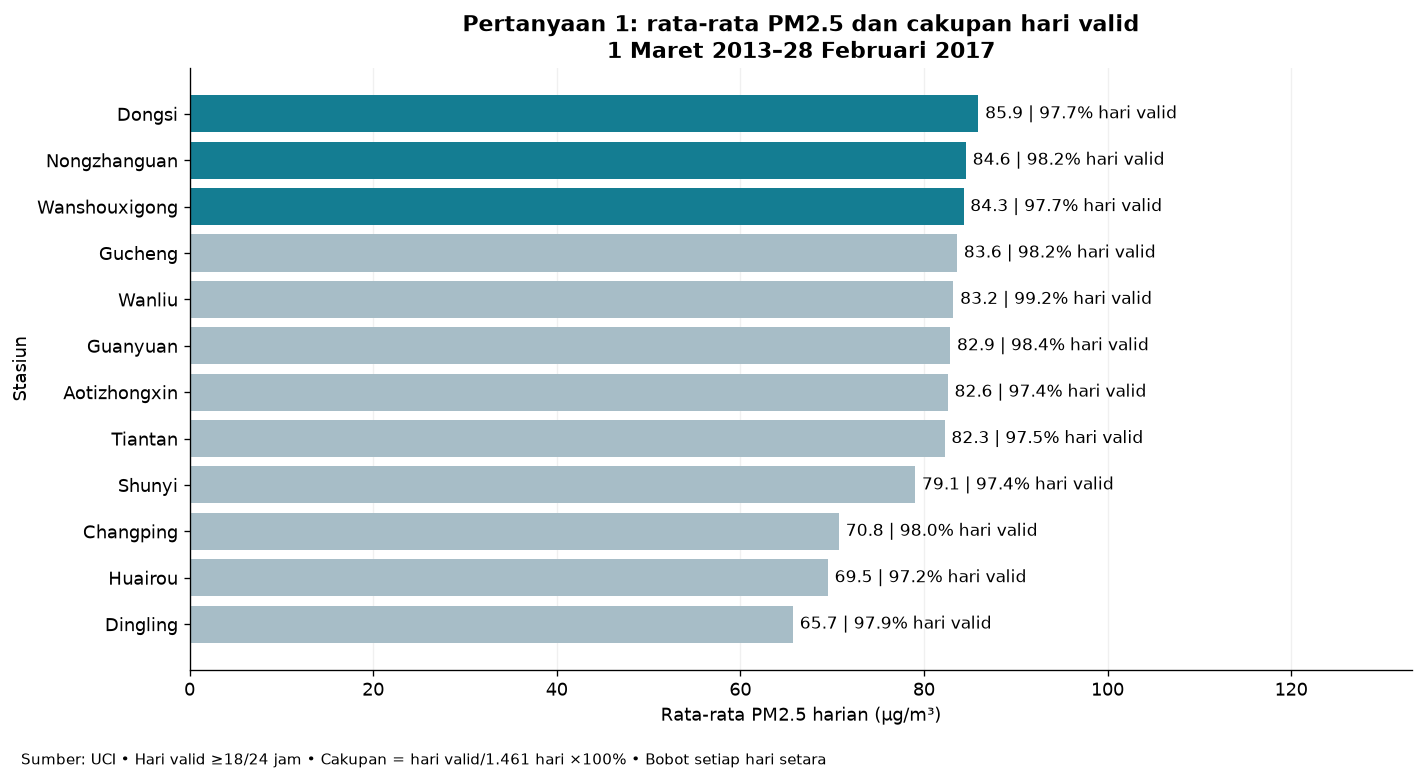

In [7]:
fig, ax = plt.subplots(figsize=(12,6.5))
plot = station_summary.sort_values('mean_pm25')
bars = ax.barh(plot.index, plot.mean_pm25,
    color=['#147d92' if s in station_summary.head(3).index else '#a7bdc7' for s in plot.index])
ax.bar_label(bars, labels=[f'{row.mean_pm25:.1f} | {row.valid_days_pct:.1f}% hari valid'
    for _, row in plot.iterrows()], padding=4, fontsize=10)
ax.set(xlabel='Rata-rata PM2.5 harian (µg/m³)', ylabel='Stasiun',
       title='Pertanyaan 1: rata-rata PM2.5 dan cakupan hari valid\n1 Maret 2013–28 Februari 2017',
       xlim=(0,plot.mean_pm25.max()*1.55))
ax.grid(axis='x', alpha=.18)
ax.set_axisbelow(True)
fig.text(.02,.01,'Sumber: UCI • Hari valid ≥18/24 jam • Cakupan = hari valid/1.461 hari ×100% • Bobot setiap hari setara', fontsize=9)
fig.tight_layout(rect=(0,.035,1,1))
fig.savefig(BASE/'figures'/'01_stasiun.png', bbox_inches='tight')
plt.show()

**Jawaban dan insight pertanyaan 1 (1 Maret 2013–28 Februari 2017):**

| Prioritas | Stasiun | Rata-rata PM2.5 harian (µg/m³) | Hari valid / seluruh hari | Cakupan hari valid |
| --- | --- | ---: | ---: | ---: |
| 1 | Dongsi | 85,94 | 1.428 / 1.461 | 97,74% |
| 2 | Nongzhanguan | 84,58 | 1.435 / 1.461 | 98,22% |
| 3 | Wanshouxigong | 84,32 | 1.428 / 1.461 | 97,74% |

Ketiga lokasi menjadi prioritas audit pemantauan berdasarkan rata-rata yang lebih
tinggi. Warna aksen menandai prioritas, bukan tingkat bahaya. Cakupan mendekati 98%
memberi konteks kelengkapan; missingness tetap mungkin tidak acak. Hasil sensor tidak
langsung mewakili paparan penduduk atau membuktikan penyebab emisi.

### Pertanyaan 2 — prioritas waktu
> Selama 1 Maret 2013–28 Februari 2017, bulan kalender apa yang memiliki rata-rata PM2.5 tertinggi dan terendah, serta berapa selisihnya, sebagai dasar penjadwalan peningkatan pemantauan kualitas udara?

Grafik garis membandingkan dua belas bulan kalender dalam periode penelitian.
Label menandai rata-rata tertinggi dan terendah; selisihnya dicantumkan dalam judul.
Bidang berwarna menunjukkan rentang antar-tahun yang tersedia, bukan interval kepercayaan.

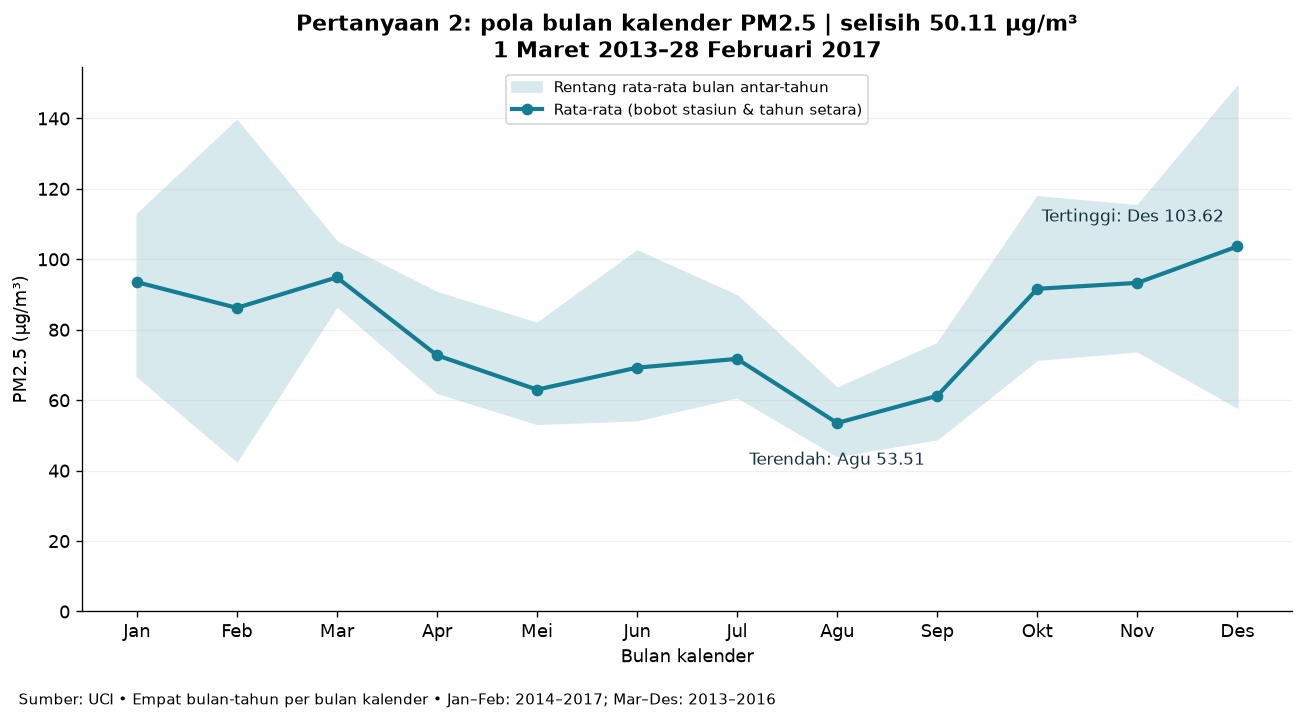

In [8]:
fig, ax = plt.subplots(figsize=(11,6))
ax.fill_between(month_summary.index, month_summary.min_pm25, month_summary.max_pm25,
                color='#d8e9ee', label='Rentang rata-rata bulan antar-tahun')
ax.plot(month_summary.index, month_summary.mean_pm25, marker='o', color='#147d92',
        linewidth=2.5, label='Rata-rata (bobot stasiun & tahun setara)')
for month, name in [(peak_month, 'Tertinggi'), (low_month, 'Terendah')]:
    value = month_summary.loc[month, 'mean_pm25']
    ax.annotate(f'{name}: {MONTHS[month-1]} {value:.2f}', xy=(month,value),
                xytext=(-8,15) if month == peak_month else (0,-25),
                textcoords='offset points', ha='right' if month == peak_month else 'center',
                color='#17313c', fontsize=10)
ax.set(xticks=range(1,13), xticklabels=MONTHS, ylim=(0,None),
       xlabel='Bulan kalender', ylabel='PM2.5 (µg/m³)',
       title=f'Pertanyaan 2: pola bulan kalender PM2.5 | selisih {monthly_gap:.2f} µg/m³\n1 Maret 2013–28 Februari 2017')
ax.legend(fontsize=9, loc='upper center')
ax.grid(axis='y', alpha=.18)
fig.text(.02,.01,'Sumber: UCI • Empat bulan-tahun per bulan kalender • Jan–Feb: 2014–2017; Mar–Des: 2013–2016', fontsize=9)
fig.tight_layout(rect=(0,.035,1,1))
fig.savefig(BASE/'figures'/'02_bulanan.png', bbox_inches='tight')
plt.show()

**Jawaban dan insight pertanyaan 2 (1 Maret 2013–28 Februari 2017):**
rata-rata tertinggi terdapat pada **Desember (103,62 µg/m³)** dan terendah pada
**Agustus (53,51 µg/m³)**; selisihnya **50,11 µg/m³**. Temuan ini mendukung penjadwalan
peningkatan pemantauan menjelang dan selama Desember berdasarkan pola historis.
Rentang antar-tahun menunjukkan pola tidak identik setiap tahun.

**Rangkuman Explanatory Analysis:** grafik 1 beserta tabel menjawab lokasi, rata-rata,
dan cakupan hari valid pada pertanyaan 1; grafik 2 menjawab bulan ekstrem dan
selisih pada pertanyaan 2. Kedua grafik memakai periode **1 Maret 2013–28 Februari 2017**
yang sama dengan rumusan awal. Hubungan deskriptif ini tidak membuktikan penyebab emisi.

## Analisis Lanjutan (Opsional)

### Clustering dengan Binning (Tanpa Machine Learning)
**Tujuan:** mengelompokkan stasiun-hari berdasarkan konsentrasi PM2.5 untuk membedakan
lokasi dengan seringnya konsentrasi tinggi, walaupun rata-ratanya serupa.
Metode `pd.cut` menggunakan batas tetap: **[0,25], (25,50], (50,100], (100,150], (150,∞)** µg/m³.
Batas ini dipilih sebagai interval deskriptif yang mudah dibandingkan, **bukan AQI,
standar kesehatan, atau ambang regulasi**. Nilai batas termasuk kelompok di sebelah kiri:
25 masuk 0–25 dan 150 masuk >100–150. Hari tidak valid tetap kosong, bukan kelompok terendah.

Tidak ada pelatihan model, K-Means, atau algoritma machine learning. RFM tidak dipakai
karena dataset tidak memuat pelanggan, transaksi, atau pengeluaran. Geospatial tidak
dipaksakan karena koordinat stasiun tidak tersedia dalam CSV.

Persentase kelompok memakai denominator **hari valid per stasiun**. Pembaca perlu
memeriksa cakupan di tabel EDA sebelum membandingkan proporsinya.

concentration_group,0–25,>25–50,>50–100,>100–150,>150
station,,,,,
Aotizhongxin,261,304,431,239,188
Changping,357,330,411,188,146
Dingling,444,308,373,172,133
Dongsi,253,287,434,251,203
Guanyuan,251,315,442,243,186
Gucheng,225,328,466,229,186
Huairou,352,348,388,187,145
Nongzhanguan,267,294,436,229,209
Shunyi,304,292,425,217,185


concentration_group,0–25,>25–50,>50–100,>100–150,>150
station,,,,,
Aotizhongxin,18.34,21.36,30.29,16.80,13.21
Changping,24.93,23.04,28.70,13.13,10.20
Dingling,31.05,21.54,26.08,12.03,9.30
Dongsi,17.72,20.10,30.39,17.58,14.22
Guanyuan,17.47,21.92,30.76,16.91,12.94
Gucheng,15.69,22.87,32.50,15.97,12.97
Huairou,24.79,24.51,27.32,13.17,10.21
Nongzhanguan,18.61,20.49,30.38,15.96,14.56
Shunyi,21.36,20.52,29.87,15.25,13.00


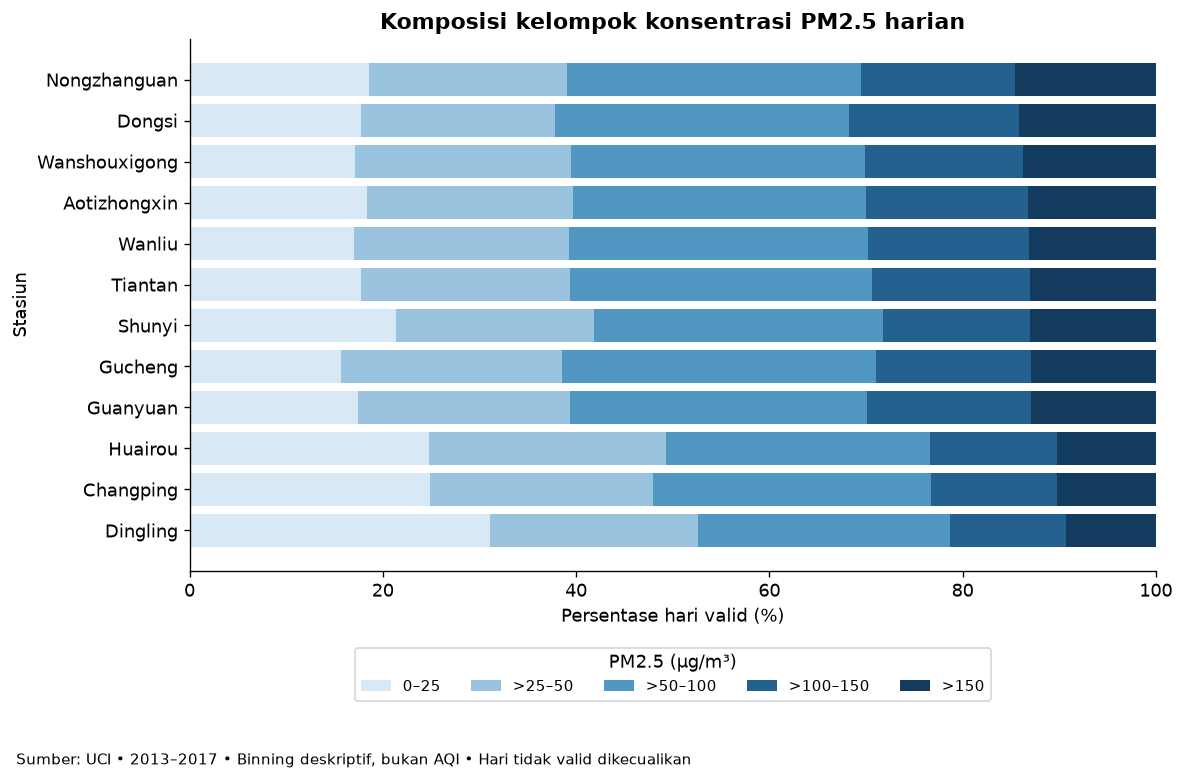

,persen_hari_di_atas_150
station,
Nongzhanguan,14.564460
Dongsi,14.215686
Wanshouxigong,13.725490
Aotizhongxin,13.211525
Wanliu,13.181504
Tiantan,13.052632
Shunyi,13.000703
Gucheng,12.970711
Guanyuan,12.943633


In [9]:
group_counts = pd.crosstab(daily.station, daily.concentration_group).reindex(columns=LABELS, fill_value=0)
group_pct = group_counts.div(group_counts.sum(axis=1), axis=0) * 100
display(group_counts)
display(group_pct.round(2))
assert np.allclose(group_pct.sum(axis=1), 100)
order = group_pct['>150'].sort_values().index
fig, ax = plt.subplots(figsize=(10,6.5))
left = np.zeros(len(order))
for label, color in zip(LABELS, COLORS):
    values = group_pct.loc[order, label]
    ax.barh(order, values, left=left, label=label, color=color)
    left += values.to_numpy()
ax.set(xlim=(0,100), xlabel='Persentase hari valid (%)', ylabel='Stasiun',
       title='Komposisi kelompok konsentrasi PM2.5 harian')
ax.legend(title='PM2.5 (µg/m³)', ncol=5, bbox_to_anchor=(.5,-.13), loc='upper center', fontsize=9)
fig.text(.02,.01,'Sumber: UCI • 2013–2017 • Binning deskriptif, bukan AQI • Hari tidak valid dikecualikan', fontsize=9)
fig.tight_layout(rect=(0,.055,1,1))
fig.savefig(BASE/'figures'/'03_binning.png', bbox_inches='tight')
plt.show()
display(group_pct['>150'].sort_values(ascending=False).rename('persen_hari_di_atas_150').to_frame())

**Rangkuman / insight Analisis Lanjutan:** Nongzhanguan memiliki proporsi
stasiun-hari >150 µg/m³ tertinggi, yaitu 14.56% dari hari validnya.
Proporsi ini melengkapi rata-rata untuk menyusun prioritas investigasi episode polusi.
Pengelompokan tidak mengukur risiko medis dan batas interval dapat memengaruhi hasil.

## Conclusion & Recommendation

### Pertanyaan 1 — prioritas lokasi
> Selama 1 Maret 2013–28 Februari 2017, tiga stasiun mana yang memiliki rata-rata PM2.5 harian tertinggi, berapa nilai rata-rata dan persentase hari validnya, sebagai dasar penentuan prioritas audit pemantauan kualitas udara?

**Kesimpulan:** selama 1 Maret 2013–28 Februari 2017, tiga stasiun dengan rata-rata
PM2.5 harian tertinggi adalah **Dongsi (85,94 µg/m³; cakupan 97,74%)**,
**Nongzhanguan (84,58 µg/m³; cakupan 98,22%)**, dan **Wanshouxigong (84,32 µg/m³;
cakupan 97,74%)**. Persentase dihitung dari hari valid terhadap 1.461 hari penelitian.
Keanggotaan tiga prioritas tetap sama pada syarat 24 jam dan tanggal valid bersama,
meskipun peringkat kedua/ketiga bertukar.

**Action item 1:** tim pemantauan mendahulukan audit kalibrasi sensor dan kelengkapan
data pada ketiga stasiun, kemudian menyandingkan episode konsentrasi tinggi dengan
catatan emisi serta meteorologi untuk menentukan investigasi lanjutan.

### Pertanyaan 2 — prioritas waktu
> Selama 1 Maret 2013–28 Februari 2017, bulan kalender apa yang memiliki rata-rata PM2.5 tertinggi dan terendah, serta berapa selisihnya, sebagai dasar penjadwalan peningkatan pemantauan kualitas udara?

**Kesimpulan:** pada periode 1 Maret 2013–28 Februari 2017, **Desember** memiliki
rata-rata PM2.5 tertinggi (**103,62 µg/m³**) dan **Agustus** terendah (**53,51 µg/m³**),
dengan selisih **50,11 µg/m³**. Nilai ini merupakan rata-rata bulan kalender dengan
bobot stasiun, kemudian tahun, setara pada tahap agregasinya.

**Action item 2:** gunakan Desember sebagai prioritas jadwal peningkatan pemantauan
dan pemeriksaan kesiapan alat berdasarkan pola historis; validasi dengan data terbaru
sebelum menerapkannya pada operasi masa kini.

**Tindak lanjut analisis lanjutan:** pantau persentase hari dengan ≥18 jam valid
dan proporsi kelompok >150 µg/m³ untuk mengevaluasi kelengkapan serta frekuensi episode.

**Batasan:** missingness mungkin tidak acak; batas 18 jam merupakan pilihan proyek;
outlier dipertahankan karena tidak ada bukti sensor gagal; stasiun tidak mewakili
paparan populasi; pola historis bukan ramalan; perbandingan bukan inferensi kausal.
Penggabungan bulan kalender menggunakan jendela tahun berbeda untuk Jan–Feb versus Mar–Des.